In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Checking database filtering

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV results for Martin Kozak
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0"


DatabasePath=OctopusData+"/03-Bulk3D/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


In [3]:
data=pd.read_csv("Database.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data.dtypes

##JobID                           float64
RunDate                           float64
kgrid                             float64
realmesh                          float64
lambda1                           float64
tau1                              float64
Efield1                           float64
PolarizationAngle                 float64
CEP1                              float64
lambda2                           float64
tau2                              float64
Efield2                           float64
CEP2                              float64
delay                             float64
CrossPolar                        float64
TheoryLevel                       float64
InducedFields                     float64
ProbeFieldAmplitude (au)          float64
ProbeFieldDelay (s)               float64
Functional                        float64
FrozenHxc                         float64
MoveIon                           float64
NeMax                             float64
NeFinal                           

In [4]:
data=datafull
# data=data[data.Efield2!=0]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy afterpulse (eV),PoyntingEnergyFinal(eV),Eext_peak (V/m),N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2,5882467.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.0,0.0,1.030000e-06,...,0.008671,0.042221,-3.133202e+14,4.712362e+26,1.570724e+40,1.570787e+40,3.0,2.0,3087.5,1350.561171
3,5882393.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.0,0.0,1.600000e-06,...,0.013881,0.041614,-1.059148e+14,4.433284e+26,1.477840e+40,1.477761e+40,3.0,2.0,3175.0,1350.561171
4,5882390.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.0,0.0,1.600000e-06,...,0.007297,0.030018,-4.980174e+13,2.513958e+26,8.378722e+39,8.379861e+39,3.0,2.0,3262.5,1350.561171
5,5882469.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.0,0.0,1.030000e-06,...,0.012748,0.048031,-3.211832e+14,6.600577e+26,2.200183e+40,2.200192e+40,3.0,2.0,3100.0,1350.561171
6,5882460.0,20180908.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.0,0.0,1.030000e-06,...,0.003740,0.033314,-1.481377e+14,2.567658e+26,8.554624e+39,8.558859e+39,3.0,2.0,3312.5,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1949,19224322.0,20200521.0,24.0,0.434637,1.030000e-06,3.000000e-14,2.000000e+09,0.0,0.0,5.150000e-07,...,-0.000129,0.000249,2.698554e+11,3.140216e+25,7.196335e+38,1.046739e+39,3.0,2.0,3750.0,1382.278166
1950,20077079.0,20200621.0,24.0,0.434637,1.030000e-06,3.000000e-14,2.000000e+09,0.0,0.0,5.150000e-07,...,-0.000183,0.000418,2.350072e+11,1.564645e+25,2.530057e+38,5.215482e+38,3.0,2.0,3750.0,1382.278166
1962,19643664.0,20200609.0,24.0,0.434637,8.000000e-07,3.000000e-14,1.000000e+10,0.0,0.0,8.000000e-07,...,0.005320,0.022997,-2.931054e+13,2.051271e+26,5.958637e+39,6.837569e+39,3.0,2.0,6875.0,3417.629821
1963,19643663.0,20200609.0,24.0,0.434637,8.000000e-07,3.000000e-14,1.000000e+10,0.0,0.0,8.000000e-07,...,0.004933,0.022997,1.630387e+13,1.762805e+26,5.841607e+39,5.876016e+39,3.0,2.0,7375.0,3417.629821


In [15]:
datafull=data
data = data[data.lambda1==2656e-9]
data.tau1*1E15
data[data.tau1 > 13.945e-15*0.99]

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy afterpulse (eV),PoyntingEnergyFinal(eV),Eext_peak (V/m),N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,441962.0,20210429.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.785398,0.000000,0.000003,...,0.0,0.314102,-8.768611e+14,2.479292e+27,1.779908e+41,1.777907e+41,1.0,0.0,3266.25,1153.010893
1,441963.0,20210429.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.785398,0.000000,0.000003,...,0.0,39.649807,-2.175106e+15,8.573567e+28,6.148288e+42,6.148130e+42,1.0,0.0,3266.25,1153.010893
2,449798.0,20210514.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.785398,0.448799,0.000003,...,0.0,0.316776,-7.618492e+14,2.495643e+27,1.791551e+41,1.789633e+41,1.0,0.0,3266.25,1153.010893
3,449794.0,20210514.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.785398,1.570796,0.000003,...,0.0,0.317617,-4.948564e+13,2.494893e+27,1.790949e+41,1.789095e+41,1.0,0.0,3266.25,1153.010893
4,449800.0,20210514.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.785398,0.349066,0.000003,...,0.0,0.315729,-8.201734e+14,2.488249e+27,1.786287e+41,1.784331e+41,1.0,0.0,3266.25,1153.010893
5,449795.0,20210514.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.785398,1.047198,0.000003,...,0.0,0.316965,-4.309257e+14,2.489685e+27,1.787250e+41,1.785361e+41,1.0,0.0,3266.25,1153.010893
6,449804.0,20210515.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.785398,0.785398,0.000003,...,0.0,39.869166,-1.904455e+15,8.640622e+28,6.195831e+42,6.196215e+42,1.0,0.0,3266.25,1153.010893
7,449799.0,20210514.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.785398,0.392699,0.000003,...,0.0,0.316218,-7.944759e+14,2.491754e+27,1.788784e+41,1.786844e+41,1.0,0.0,3266.25,1153.010893
8,449802.0,20210513.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.785398,1.570796,0.000003,...,0.0,39.885719,-3.287811e+15,8.677171e+28,6.221728e+42,6.222424e+42,1.0,0.0,3266.25,1153.010893
9,449805.0,20210513.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.785398,0.523599,0.000003,...,0.0,39.780439,-1.128108e+15,8.618385e+28,6.179974e+42,6.180269e+42,1.0,0.0,3266.25,1153.010893


# Generating the final HHG spectrum

In [16]:
!$QuantumLaPsources/octopus_slabs/Libs/plotHHGspectra.py

  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ====== PULSE 1 =====
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** Efield1*           size = 2
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** wavelength1*       size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** pulse duration*    size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** CEP1               size = 8
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ====== PULSE 2 =====
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** Efield2*           size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** wavelength2*       size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** pulse duration*    size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserP

Size of HHG file: 6000
** Info: interpolating...
** Debug: 59.99999994
** Debug: checking length of new mesh: (600,)
59 deg.
octopus-td.449794*.log
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field3E9-CEP0.5-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0.5e-15-SinSquared
Size of HHG file: 6000
** Info: interpolating...
** Debug: 90.0
** Debug: checking length of new mesh: (600,)
90 deg.
** Info: Exporting to file HHGspectrumWithCEP-wavelength2656nm-Efield3000000000.csv
** Preparing plot...
  octopus_slabs.Libs.libPlotting - plot2dHeatMap_HHG - INFO - 4800
  octopus_slabs.Libs.libPlotting - plot2dHeatMap_HHG - INFO - 4800
  octopus_slabs.Libs.libPlotting - plot2dHeatMap_HHG - INFO - 4800
  matplotlib.font_manager - _findfont_cached - WARNING - findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
  matplotlib.font_

Size of HHG file: 6000
** Info: interpolating...
** Debug: 30.0000006
** Debug: checking length of new mesh: (600,)
30 deg.
octopus-td.449804*.log
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.05E10-CEP0.25-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0.5e-15-SinSquared
Size of HHG file: 6000
** Info: interpolating...
** Debug: 45.0
** Debug: checking length of new mesh: (600,)
45 deg.
octopus-td.449803*.log
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.05E10-CEP0.333333333-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0.5e-15-SinSquared
Size of HHG file: 6000
** Info: interpolating...
** Debug: 59.99999994
** Debug: checking length of new mesh: (600,)
59 deg.
octopus-td.449802*

In [22]:
!ls HHGspectrum*.png

HHGspectrumWithCEP-wavelength2656nm-Efield10500000000.png
HHGspectrumWithCEP-wavelength2656nm-Efield3000000000.png


In [23]:
!display HHGspectrumWithCEP-wavelength2656nm-Efield10500000000.png

In [24]:
!display HHGspectrumWithCEP-wavelength2656nm-Efield3000000000.png

^C


# Refining the energy range

In [3]:
from scipy.constants import h, c, e
h*c/e/250E-9

4.959367937328011

Remaining problem is: the energy of the spectrum is far too high. We need to decrease it by a factor of 10. 

For doing so, it is proposed to play with the temporal resolution. Following Heisenberg uncertainty / Noether theorem, we shall simply try to decrease number of samples by 10. Let's see if this brings us more resolution or less. In principle, decreasing time precision should increase energy precision. 

In [1]:
# from scipy.fft import fft, fftfreq, fftshift
from numpy import fft
import numpy as np
from scipy.constants import c, hbar, e
import matplotlib.pyplot as plt

# del t, y
# number of signal points
N = 10_000 #this controls timestep, it does not control time window duration. Then it acts only on the maximum energy one can address in Fourier spectrum

wavelength = 2300e-9; tau=13e-15
# wavelength = 800e-9; tau=30e-15
omega = 2*np.pi*c/wavelength
T = 2*np.pi/omega
sigma_tau=tau/(2.*np.sqrt(2.*np.log(2.)))

print("One-cycle period: "+str(T)+" seconds")
print("Frequency in Hz:  "+str(omega/1E15)+" PHz")

t0 = 2*tau #central time
tmin = 0; tmax = 10*t0; #size of the window: controls energy precision. 
# Solution for increasing FFT spectrum precision: increase size of initial signal table, just fill it with zeros.
t = np.linspace(tmin, tmax, N, endpoint=False)
TimeStep=np.diff(t)[0]
print("Timestep: "+str(TimeStep)+" s")
# print(omega*t)
y = np.exp(-0.5*((t-t0)/sigma_tau)**2) * np.sin(omega*t) #+ 0.5*np.sin(80.0 * 2.0*np.pi*t)
# y.resize(30000,)

One-cycle period: 7.671974189557498e-15 seconds
Frequency in Hz:  0.818978942308197 PHz
Timestep: 2.6e-17 s


## Definition of pulse

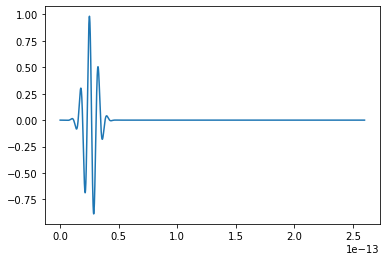

In [2]:
plt.figure()
plt.plot(t,y)
plt.show()

## Definition of Fourier part

In [3]:
yf = fft.rfft(y)
xf = 2.*np.pi*fft.rfftfreq(len(t), d=TimeStep)
# xf = fft.fftshift(xf) #no effect in real space
photon_energy = hbar*xf/e #converting in eV

yplot = yf
# yplot = fft.fftshift(yf) #no effect in real space

print(np.shape(photon_energy))
print(np.shape(yplot))

(5001,)
(5001,)


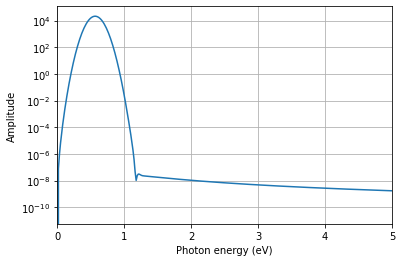

In [4]:
plt.figure()
# plt.semilogy(xf, 1.0/N * np.abs(yplot)) #amplitude
plt.semilogy(photon_energy, photon_energy**2 * np.abs(yplot)**2) #Larmor formula
# plt.xlabel("Frequency (Hz)")
plt.xlabel("Photon energy (eV)")
plt.ylabel("Amplitude")
plt.xlim(0,5)
plt.grid()
plt.show()

## Trying to increase size of the signal

In [5]:
print(np.shape(y))
print(np.shape(t))

(10000,)
(10000,)


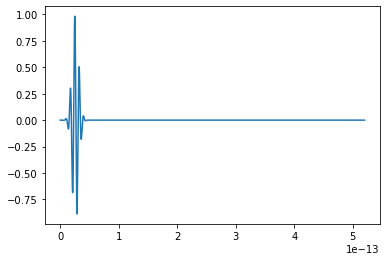

In [12]:
t2 = np.arange(tmin, 2 * tmax, TimeStep)
y.resize(20_000,refcheck=False)

plt.figure()
plt.plot(t2,y)
plt.show()

In [16]:
a=np.array([[1,2,3,4], [4,3,2,1], [5,3,6,2]])

In [17]:
np.mean(a)

3.0